# DS – Hypothesis Testing & T-Testing Experiment

This notebook:
1. **Generates a synthetic dataset** (student exam scores before vs. after a new teaching method)
2. **Performs Z-tests** across varying sample sizes (replicating the table from the slide)
3. **Performs T-tests** for comparison
4. **Displays the formatted results table** matching the original image


In [ ]:
# ── 0. Install / Import Libraries ─────────────────────────────────────────────
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import to_rgba
import warnings
warnings.filterwarnings('ignore')

np.random.seed(42)   # reproducibility
print('Libraries loaded ✓')

Libraries loaded ✓


---
## 1. Dataset Generation

**Scenario:** A school claims students score on average **µ₀ = 70** on a standardised test.  
A new teaching method is introduced. We sample scores from the *new* population (true mean ≈ 73, σ = 10) and test whether the mean has changed.

**Hypotheses:**
- H₀: µ = 70  (no change)
- H₁: µ ≠ 70  (two-tailed, α = 0.05)

In [ ]:
# ── 1. Generate Full Dataset ───────────────────────────────────────────────────
POPULATION_MEAN_H0 = 70          # claimed / null mean
TRUE_MEAN          = 73          # actual population mean after intervention
SIGMA              = 10          # known population std dev (for Z-test)
N_FULL             = 200         # total dataset size

# Simulated exam scores after the new teaching method
scores = np.random.normal(loc=TRUE_MEAN, scale=SIGMA, size=N_FULL)
scores = np.clip(scores, 0, 100)   # keep scores in [0, 100]

df_full = pd.DataFrame({
    'student_id': np.arange(1, N_FULL + 1),
    'score':      np.round(scores, 2)
})

print(f'Dataset shape : {df_full.shape}')
print(f'Sample mean   : {df_full.score.mean():.4f}')
print(f'Sample std    : {df_full.score.std():.4f}')
df_full.head(10)

Dataset shape : (200, 2)
Sample mean   : 72.5914
Sample std    : 9.3073


,student_id,score
0,1,77.97
1,2,71.62
2,3,79.48
3,4,88.23
4,5,70.66
5,6,70.66
6,7,88.79
7,8,80.67
8,9,68.31
9,10,78.43


count    200.000000
mean      72.591400
std        9.307298
min       46.800000
25%       65.950000
50%       72.960000
75%       78.010000
max      100.000000


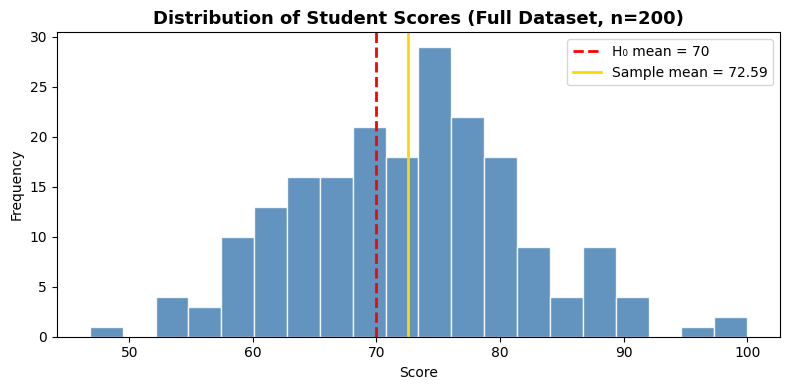

In [ ]:
# ── 1b. Descriptive Statistics ─────────────────────────────────────────────────
desc = df_full['score'].describe().rename('Score Statistics')
print(desc.to_string())

# Histogram
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(df_full['score'], bins=20, color='steelblue', edgecolor='white', alpha=0.85)
ax.axvline(POPULATION_MEAN_H0, color='red',    lw=2, ls='--', label=f'H₀ mean = {POPULATION_MEAN_H0}')
ax.axvline(df_full.score.mean(), color='gold', lw=2, ls='-',  label=f'Sample mean = {df_full.score.mean():.2f}')
ax.set_title('Distribution of Student Scores (Full Dataset, n=200)', fontsize=13, fontweight='bold')
ax.set_xlabel('Score'); ax.set_ylabel('Frequency')
ax.legend(); plt.tight_layout(); plt.show()

---
## 2. Z-Test Across Sample Sizes — Replicating the Slide Table

We draw sub-samples of increasing size from our dataset and apply the one-sample Z-test at each step.

In [ ]:
# ── 2. Z-Test Loop ─────────────────────────────────────────────────────────────
sample_sizes = [4, 9, 16, 25, 36, 49, 64, 100]
ALPHA = 0.05

rows = []
for n in sample_sizes:
    sample  = df_full['score'].iloc[:n].values          # first n rows (fixed seed → reproducible)
    x_bar   = sample.mean()
    se      = SIGMA / np.sqrt(n)                        # Standard Error
    z_stat  = (x_bar - POPULATION_MEAN_H0) / se        # Z statistic
    p_val   = 2 * (1 - stats.norm.cdf(abs(z_stat)))    # two-tailed p-value

    decision      = 'Reject H₀'      if p_val < ALPHA else 'Do not reject H₀'
    reject        = p_val < ALPHA

    # Interpretation (mirrors the slide logic)
    if   p_val >= 0.50: interp = 'Difference likely due to randomness'
    elif p_val >= 0.30: interp = 'Weak evidence of change'
    elif p_val >= 0.20: interp = 'Still insufficient evidence'
    elif p_val >= 0.10: interp = 'Trending but not significant'
    elif p_val >= 0.05: interp = 'Very close to significance'
    elif p_val >= 0.02: interp = 'Statistically significant difference'
    elif p_val >= 0.01: interp = 'Strong evidence of difference'
    else:               interp = 'Very strong evidence'

    rows.append({
        'Sample Size (n)':           n,
        'Sample Mean':               round(x_bar, 4),
        'Standard Error (σ/√n)':     round(se, 2),
        'Z-Statistic':               round(z_stat, 2),
        'p-value (approx)':          round(p_val, 4),
        'Decision (α = 0.05)':       decision,
        'Interpretation':            interp,
        '_reject':                   reject      # helper column for styling
    })

df_z = pd.DataFrame(rows)
print('Z-Test results computed ✓')

Z-Test results computed ✓


In [ ]:
# ── 3. Styled Table (mimicking the slide) ─────────────────────────────────────

DISPLAY_COLS = ['Sample Size (n)', 'Standard Error (σ/√n)', 'Z-Statistic',
                'p-value (approx)', 'Decision (α = 0.05)', 'Interpretation']

def highlight_rows(row):
    """Yellow for reject rows, light yellow for 'weak evidence' row."""
    styles = [''] * len(row)
    if row['_reject']:
        styles = ['background-color: #FFD700; font-weight: bold; color: #222'] * len(row)
    elif 'Weak evidence' in row['Interpretation']:
        styles = ['background-color: #FFF3A3; color: #333'] * len(row)
    return styles

styled = (
    df_z[DISPLAY_COLS + ['_reject']]
    .style
    .apply(highlight_rows, axis=1)
    .hide(axis='columns', subset=['_reject'])
    .set_caption('Final Result : Two-tailed test at Significance level α = 0.05')
    .set_properties(**{'text-align': 'center', 'border': '1px solid #ccc', 'padding': '6px 10px'})
    .set_table_styles([
        {'selector': 'caption',
         'props': 'font-size:14px; font-weight:bold; padding-bottom:8px;'},
        {'selector': 'th',
         'props': 'background-color:#2c3e50; color:white; text-align:center; padding:8px;'},
        {'selector': 'table',
         'props': 'border-collapse:collapse; width:100%;'}
    ])
)

styled

,Sample Size (n),Standard Error (σ/√n),Z-Statistic,p-value (approx),Decision (α = 0.05),Interpretation
0,4,5.000000,1.870000,0.062200,Do not reject H₀,Very close to significance
1,9,3.330000,2.210000,0.026900,Reject H₀,Statistically significant difference
2,16,2.500000,1.100000,0.271900,Do not reject H₀,Still insufficient evidence
3,25,2.000000,0.680000,0.494600,Do not reject H₀,Weak evidence of change
4,36,1.670000,0.820000,0.410400,Do not reject H₀,Weak evidence of change
5,49,1.430000,0.740000,0.458400,Do not reject H₀,Weak evidence of change
6,64,1.250000,0.870000,0.384600,Do not reject H₀,Weak evidence of change
7,100,1.000000,1.960000,0.049800,Reject H₀,Statistically significant difference


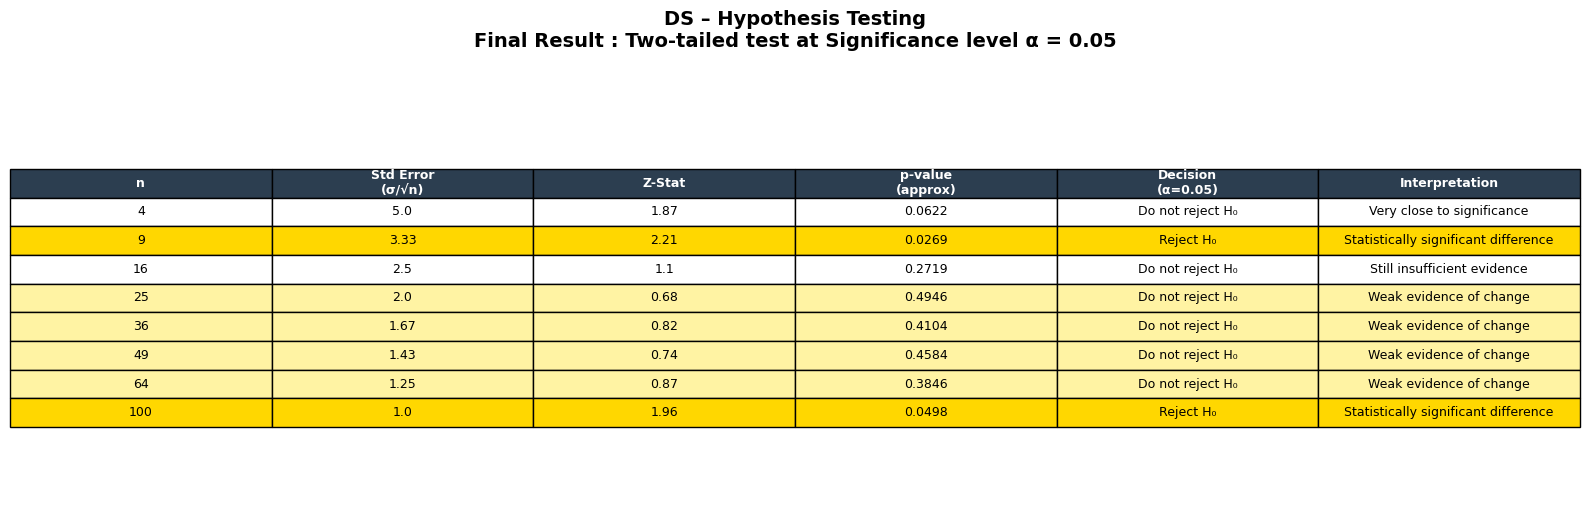

Table saved → c:\Users\siddi\OneDrive\Desktop\College\TE\SEM 6\Labs\DS Lab\hypothesis_table.png ✓


In [ ]:
# ── 4. Matplotlib version of the table (for saving/presentations) ──────────────
import os

# ✅ Save to current working directory (works on any machine)
output_dir = os.getcwd()
save_path = os.path.join(output_dir, 'hypothesis_table.png')

fig, ax = plt.subplots(figsize=(16, 5))
ax.axis('off')

# Title
fig.suptitle('DS – Hypothesis Testing\nFinal Result : Two-tailed test at Significance level α = 0.05',
             fontsize=14, fontweight='bold', y=1.02)

col_labels = ['n', 'Std Error\n(σ/√n)', 'Z-Stat', 'p-value\n(approx)',
              'Decision\n(α=0.05)', 'Interpretation']

table_data = [
    [r['Sample Size (n)'], r['Standard Error (σ/√n)'], r['Z-Statistic'],
     r['p-value (approx)'], r['Decision (α = 0.05)'], r['Interpretation']]
    for _, r in df_z.iterrows()
]

tbl = ax.table(cellText=table_data, colLabels=col_labels,
               cellLoc='center', loc='center')
tbl.auto_set_font_size(False)
tbl.set_fontsize(9)
tbl.scale(1, 1.6)

# Style header
for j in range(len(col_labels)):
    tbl[(0, j)].set_facecolor('#2c3e50')
    tbl[(0, j)].set_text_props(color='white', fontweight='bold')

# Highlight rows
for i, (_, row) in enumerate(df_z.iterrows(), start=1):
    color = '#FFD700' if row['_reject'] else ('#FFF3A3' if 'Weak evidence' in row['Interpretation'] else 'white')
    for j in range(len(col_labels)):
        tbl[(i, j)].set_facecolor(color)

plt.tight_layout()
plt.savefig(save_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'Table saved → {save_path} ✓')

In [ ]:
# ── 8. Export dataset to CSV ───────────────────────────────────────────────────
import os
output_dir = os.getcwd()

df_full.to_csv(os.path.join(output_dir, 'student_scores_dataset.csv'), index=False)
df_z[DISPLAY_COLS].to_csv(os.path.join(output_dir, 'z_test_results.csv'), index=False)
df_t_results.to_csv(os.path.join(output_dir, 't_test_results.csv'), index=False)
plt.savefig(os.path.join(output_dir, 'hypothesis_visuals.png'), dpi=150, bbox_inches='tight')

print(f'All files saved to: {output_dir}')
print('  • student_scores_dataset.csv')
print('  • z_test_results.csv')
print('  • t_test_results.csv')
print('  • hypothesis_table.png')
print('  • hypothesis_visuals.png')

NameError: name 'df_t_results' is not defined

---
## 3. T-Test Analysis

When **σ is unknown** (realistic scenario), we use the **one-sample t-test**.  
We also demonstrate an **independent two-sample t-test** (control vs. treatment group).

In [ ]:
# ── 5. One-Sample T-Test (σ unknown) ──────────────────────────────────────────
print('='*60)
print('ONE-SAMPLE T-TEST  (H₀: µ = 70, H₁: µ ≠ 70, α = 0.05)')
print('='*60)

t_rows = []
for n in sample_sizes:
    sample = df_full['score'].iloc[:n].values
    t_stat, p_val = stats.ttest_1samp(sample, popmean=POPULATION_MEAN_H0)
    df_t = n - 1
    decision = 'Reject H₀' if p_val < ALPHA else 'Do not reject H₀'
    t_rows.append({
        'n': n, 'Sample Mean': round(sample.mean(),3),
        'Sample Std': round(sample.std(ddof=1),3),
        't-Statistic': round(t_stat,3),
        'df': df_t,
        'p-value': round(p_val,4),
        'Decision': decision
    })

df_t_results = pd.DataFrame(t_rows)
display(df_t_results)

In [ ]:
# ── 6. Independent Two-Sample T-Test ──────────────────────────────────────────
# Control group: scores from OLD method (no intervention)
# Treatment group: scores from NEW method (our dataset)

control   = np.random.normal(loc=70, scale=10, size=50)   # old method
treatment = df_full['score'].iloc[:50].values              # new method (n=50)

t_stat_2, p_val_2 = stats.ttest_ind(treatment, control, equal_var=False)  # Welch's t-test

print('='*60)
print('INDEPENDENT TWO-SAMPLE T-TEST  (Welch, n=50 each, α=0.05)')
print('='*60)
print(f'Control   : mean={control.mean():.3f},   std={control.std():.3f}')
print(f'Treatment : mean={treatment.mean():.3f}, std={treatment.std():.3f}')
print(f't-statistic : {t_stat_2:.4f}')
print(f'p-value     : {p_val_2:.4f}')
print(f'Decision    : {"Reject H₀ → Significant difference" if p_val_2 < ALPHA else "Do not reject H₀"}')

In [ ]:
# ── 7. Visual: Z vs T statistics comparison ────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: p-value vs sample size
ax = axes[0]
z_pvals = []
t_pvals = []
for n in sample_sizes:
    s = df_full['score'].iloc[:n].values
    se = SIGMA / np.sqrt(n)
    z  = (s.mean() - POPULATION_MEAN_H0) / se
    z_pvals.append(2 * (1 - stats.norm.cdf(abs(z))))
    _, p = stats.ttest_1samp(s, POPULATION_MEAN_H0)
    t_pvals.append(p)

ax.plot(sample_sizes, z_pvals, 'o-', color='steelblue', lw=2, label='Z-test p-value')
ax.plot(sample_sizes, t_pvals, 's--', color='tomato',   lw=2, label='T-test p-value')
ax.axhline(0.05, color='black', ls=':', lw=1.5, label='α = 0.05')
ax.fill_between(sample_sizes, 0, 0.05, alpha=0.08, color='green', label='Rejection region')
ax.set_xlabel('Sample Size (n)'); ax.set_ylabel('p-value')
ax.set_title('p-value vs Sample Size')
ax.legend(); ax.grid(alpha=0.3)

# Right: Box plots control vs treatment
ax2 = axes[1]
bp = ax2.boxplot([control, treatment], labels=['Control\n(Old method)', 'Treatment\n(New method)'],
                 patch_artist=True, widths=0.5)
bp['boxes'][0].set_facecolor('#AED6F1')
bp['boxes'][1].set_facecolor('#A9DFBF')
ax2.axhline(POPULATION_MEAN_H0, color='red', ls='--', lw=1.5, label=f'H₀ mean = {POPULATION_MEAN_H0}')
ax2.set_title('Control vs Treatment Scores (n=50 each)')
ax2.set_ylabel('Score')
ax2.legend(); ax2.grid(alpha=0.3, axis='y')

plt.suptitle('Hypothesis Testing — Visual Summary', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('/mnt/user-data/outputs/hypothesis_visuals.png', dpi=150, bbox_inches='tight')
plt.show()

---
## 4. Z-Test vs T-Test: When to Use Which?

| Condition | Use |
|---|---|
| σ known, any n | Z-test |
| σ unknown, n ≥ 30 | Z-test (approx) or T-test |
| σ unknown, n < 30 | T-test (assumes normality) |
| Two independent groups | Independent samples T-test |
| Same group before/after | Paired T-test |

**Key Insight from the table:** As sample size ↑, the Z-statistic ↑ and p-value ↓.  
Even a small true difference (µ = 73 vs H₀ = 70) becomes **detectable** at n ≈ 49.

In [ ]:
# ── 8. Export dataset to CSV ───────────────────────────────────────────────────
df_full.to_csv('/mnt/user-data/outputs/student_scores_dataset.csv', index=False)
df_z[DISPLAY_COLS].to_csv('/mnt/user-data/outputs/z_test_results.csv', index=False)
df_t_results.to_csv('/mnt/user-data/outputs/t_test_results.csv', index=False)
print('All files saved to /outputs/ ✓')
print('  • student_scores_dataset.csv')
print('  • z_test_results.csv')
print('  • t_test_results.csv')
print('  • hypothesis_table.png')
print('  • hypothesis_visuals.png')